# Decision Tree Regresssion pada Wine Quality

In [1]:
from pathlib import Path
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    accuracy_score,
    mean_absolute_error,
    median_absolute_error,
    r2_score,
    root_mean_squared_error,
)
from sklearn.model_selection import (
    GridSearchCV,
    KFold,
    cross_val_score,
    learning_curve,
    train_test_split,
)
from sklearn.tree import DecisionTreeRegressor, export_text, plot_tree

ROOT = Path.cwd()
while not (ROOT / "data" / "raw").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RAW_DIR = ROOT / "data" / "raw"

RANDOM_STATE = 42
TEST_SIZE = 0.2
N_FOLDS = 5
QUALITY_THRESHOLD = 6

FEATURES = [
    "fixed acidity",
    "volatile acidity",
    "citric acid",
    "residual sugar",
    "chlorides",
    "free sulfur dioxide",
    "total sulfur dioxide",
    "density",
    "pH",
    "sulphates",
    "alcohol",
]

COLORS = {
    "blue": "#2563eb",
    "red": "#dc2626",
    "green": "#16a34a",
    "gray": "#64748b",
    "orange": "#ea580c",
}

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

## 1. Data

In [2]:
def load_wine():
    frames = []
    for filename, wine_type in [
        ("winequality-red.csv", "red"),
        ("winequality-white.csv", "white"),
    ]:
        part = pd.read_csv(RAW_DIR / filename, sep=";")
        part["wine_type"] = wine_type
        frames.append(part)

    combined = pd.concat(frames, ignore_index=True)
    unique = combined.drop_duplicates().reset_index(drop=True)
    print(f"Data mentah: {len(combined)} baris | setelah deduplikasi: {len(unique)} baris")
    return unique


wine = load_wine()
wine["target"] = (wine["quality"] >= QUALITY_THRESHOLD).astype(int)
print(f"Kelas baik (quality >= {QUALITY_THRESHOLD}): {wine['target'].mean():.1%}")
wine.head()

Data mentah: 6497 baris | setelah deduplikasi: 5320 baris
Kelas baik (quality >= 6): 62.6%


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type,target
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red,1
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,red,0


**Grafik Distribusi skor quality dan sebaran alcohol.**


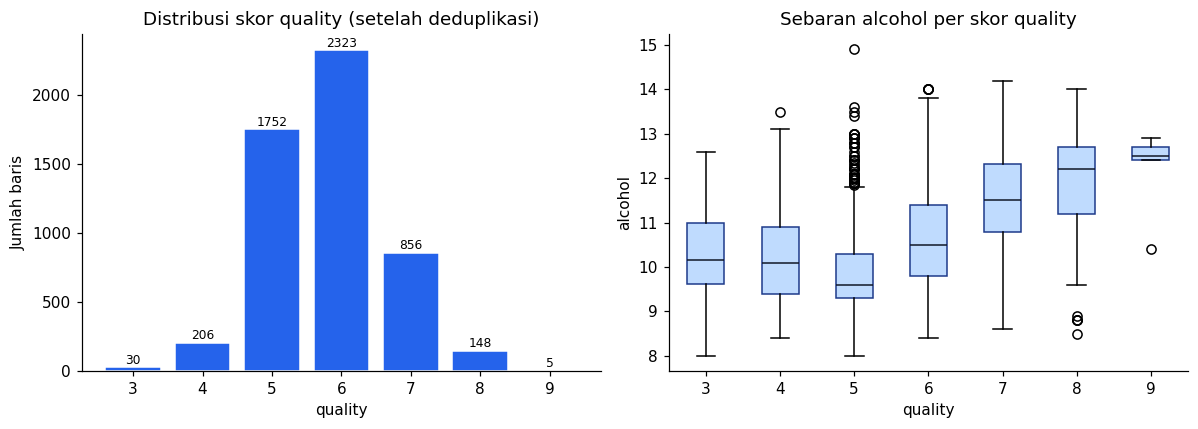

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

counts = wine["quality"].value_counts().sort_index()
axes[0].bar(counts.index.astype(int), counts.values,
            color=COLORS["blue"], edgecolor="white")
axes[0].set_title("Distribusi skor quality (setelah deduplikasi)")
axes[0].set_xlabel("quality")
axes[0].set_ylabel("Jumlah baris")
for x, y in zip(counts.index.astype(int), counts.values):
    axes[0].text(x, y + 25, str(y), ha="center", fontsize=8)

grouped = [wine.loc[wine["quality"] == level, "alcohol"].to_numpy()
           for level in counts.index.astype(int)]
box = axes[1].boxplot(grouped, tick_labels=counts.index.astype(int),
                      patch_artist=True, medianprops={"color": "#111827"})
for patch in box["boxes"]:
    patch.set_facecolor("#bfdbfe")
    patch.set_edgecolor("#1e3a8a")
axes[1].set_title("Sebaran alcohol per skor quality")
axes[1].set_xlabel("quality")
axes[1].set_ylabel("alcohol")

axes[0].grid(False)
axes[1].grid(False)
fig.tight_layout()
plt.show()

## Split Data
Split 80/20. 

In [4]:
X_reg = wine[FEATURES]
y_reg = wine["quality"]

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
cv_reg = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
print(f"Train: {len(X_train_r)} baris | test: {len(X_test_r)} baris")

Train: 4256 baris | test: 1064 baris


In [5]:
dummy_reg = DummyRegressor(strategy="mean").fit(X_train_r, y_train_r)
linear_reg = LinearRegression().fit(X_train_r, y_train_r)
default_reg = DecisionTreeRegressor(random_state=RANDOM_STATE).fit(X_train_r, y_train_r)

## Tuning hyperparameter

In [6]:
param_grid_reg = {
    "criterion": ["squared_error", "absolute_error"],
    "max_depth": list(range(2, 15)),
    "min_samples_leaf": [1, 5, 20, 50],
    "ccp_alpha": [0.0, 0.0005, 0.002, 0.005],
}

start_reg = time.time()
grid_reg = GridSearchCV(
    DecisionTreeRegressor(random_state=RANDOM_STATE),
    param_grid=param_grid_reg,
    cv=cv_reg,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    refit=True,
)
grid_reg.fit(X_train_r, y_train_r)
best_reg = grid_reg.best_estimator_

print(f"{len(grid_reg.cv_results_['params'])} kombinasi x {N_FOLDS} fold "
      f"dalam {time.time() - start_reg:.1f} detik")
print({key: grid_reg.best_params_[key] for key in param_grid_reg})
print(f"CV RMSE = {-grid_reg.best_score_:.4f}")

416 kombinasi x 5 fold dalam 104.4 detik
{'criterion': 'squared_error', 'max_depth': 7, 'min_samples_leaf': 50, 'ccp_alpha': 0.0}
CV RMSE = 0.7518


In [7]:
grid_reg_mae = GridSearchCV(
    DecisionTreeRegressor(random_state=RANDOM_STATE),
    param_grid=param_grid_reg,
    cv=cv_reg,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    refit=True,
)
grid_reg_mae.fit(X_train_r, y_train_r)
best_reg_mae = grid_reg_mae.best_estimator_

print({key: grid_reg_mae.best_params_[key] for key in param_grid_reg})
print(f"CV MAE = {-grid_reg_mae.best_score_:.4f}")

{'criterion': 'absolute_error', 'max_depth': 10, 'min_samples_leaf': 50, 'ccp_alpha': 0.0005}
CV MAE = 0.5204


In [8]:
columns = ["rank_test_score", "mean_test_score", "std_test_score", "params", "mean_fit_time"]
top_rmse = pd.DataFrame(grid_reg.cv_results_).sort_values("rank_test_score").head(10)[columns]
top_mae = pd.DataFrame(grid_reg_mae.cv_results_).sort_values("rank_test_score").head(10)[columns]
print("Objective RMSE")
display(top_rmse.round(4))
print("Objective MAE")
display(top_mae.round(4))

Objective RMSE


,rank_test_score,mean_test_score,std_test_score,params,mean_fit_time
23,1,-0.7518,0.0155,"{'ccp_alpha': 0.0, 'criterion': 'squared_error...",0.0248
123,2,-0.7519,0.0183,"{'ccp_alpha': 0.0005, 'criterion': 'squared_er...",0.0385
19,3,-0.7519,0.0184,"{'ccp_alpha': 0.0, 'criterion': 'squared_error...",0.0213
127,4,-0.7519,0.0156,"{'ccp_alpha': 0.0005, 'criterion': 'squared_er...",0.0540
131,5,-0.7525,0.0167,"{'ccp_alpha': 0.0005, 'criterion': 'squared_er...",0.0464
27,6,-0.7526,0.0166,"{'ccp_alpha': 0.0, 'criterion': 'squared_error...",0.0266
119,7,-0.7526,0.0187,"{'ccp_alpha': 0.0005, 'criterion': 'squared_er...",0.0252
15,7,-0.7526,0.0187,"{'ccp_alpha': 0.0, 'criterion': 'squared_error...",0.0265
135,9,-0.7540,0.0151,"{'ccp_alpha': 0.0005, 'criterion': 'squared_er...",0.0427
147,9,-0.7540,0.0151,"{'ccp_alpha': 0.0005, 'criterion': 'squared_er...",0.0330


Objective MAE


,rank_test_score,mean_test_score,std_test_score,params,mean_fit_time
191,1,-0.5204,0.0221,"{'ccp_alpha': 0.0005, 'criterion': 'absolute_e...",1.3362
278,2,-0.5226,0.0217,"{'ccp_alpha': 0.002, 'criterion': 'absolute_er...",0.9249
306,3,-0.5230,0.0228,"{'ccp_alpha': 0.002, 'criterion': 'absolute_er...",1.7987
295,4,-0.5230,0.0225,"{'ccp_alpha': 0.002, 'criterion': 'absolute_er...",1.1341
165,5,-0.5233,0.0201,"{'ccp_alpha': 0.0005, 'criterion': 'absolute_e...",0.8236
291,6,-0.5233,0.0243,"{'ccp_alpha': 0.002, 'criterion': 'absolute_er...",1.1051
286,7,-0.5233,0.0200,"{'ccp_alpha': 0.002, 'criterion': 'absolute_er...",1.0931
310,8,-0.5233,0.0142,"{'ccp_alpha': 0.002, 'criterion': 'absolute_er...",1.8731
187,9,-0.5233,0.0184,"{'ccp_alpha': 0.0005, 'criterion': 'absolute_e...",1.6288
60,10,-0.5240,0.0191,"{'ccp_alpha': 0.0, 'criterion': 'absolute_erro...",0.7835


## Evaluasi data test

Membandingkan lima model pada data test. Metrik yang dilaporkan mencakup MAE, RMSE, R2, MAPE, error maksimum, persentase prediksi dalam rentang 1 poin, metrik setelah pembulatan, dan akurasi ambang `quality >= 6`.

In [9]:
def evaluate_reg(model):
    y_pred = model.predict(X_test_r)
    y_true = y_test_r.to_numpy(dtype=float)
    residual = y_true - y_pred
    y_pred_rounded = np.clip(np.round(y_pred), 3, 9)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
        "MedAE": median_absolute_error(y_true, y_pred),
        "MAPE (%)": float(np.mean(np.abs(residual) / y_true) * 100),
        "max error": float(np.max(np.abs(residual))),
        "dalam +/-1 poin": float(np.mean(np.abs(residual) <= 1.0)),
        "MAE (bulat)": mean_absolute_error(y_true, y_pred_rounded),
        "RMSE (bulat)": root_mean_squared_error(y_true, y_pred_rounded),
        "R2 (bulat)": r2_score(y_true, y_pred_rounded),
        "akurasi ambang 6": accuracy_score(y_true >= QUALITY_THRESHOLD, y_pred >= QUALITY_THRESHOLD),
    }


reg_scores = pd.DataFrame({
    "dummy (mean)": evaluate_reg(dummy_reg),
    "linear regression": evaluate_reg(linear_reg),
    "tree default": evaluate_reg(default_reg),
    "tree tuned RMSE": evaluate_reg(best_reg),
    "tree tuned MAE": evaluate_reg(best_reg_mae),
}).T
reg_scores.round(4)

,MAE,RMSE,R2,MedAE,MAPE (%),max error,dalam +/-1 poin,MAE (bulat),RMSE (bulat),R2 (bulat),akurasi ambang 6
dummy (mean),0.6942,0.8676,-0.0011,0.7899,12.3916,3.2101,0.7575,0.6382,0.8859,-0.0438,0.3665
linear regression,0.5611,0.7244,0.3021,0.4570,10.0271,3.2606,0.8628,0.5019,0.7756,0.2000,0.6476
tree default,0.6626,0.9434,-0.1838,1.0000,11.5919,3.0000,0.8976,0.6626,0.9434,-0.1838,0.6927
tree tuned RMSE,0.5668,0.7330,0.2853,0.4449,10.0974,3.3976,0.8393,0.5000,0.7731,0.2050,0.6419
tree tuned MAE,0.5244,0.8065,0.1350,0.0000,9.2052,3.0000,0.9445,0.5244,0.8065,0.1350,0.7284


In [10]:
cv_mae = -cross_val_score(best_reg, X_train_r, y_train_r, cv=cv_reg,
                          scoring="neg_mean_absolute_error", n_jobs=-1)
cv_rmse = -cross_val_score(best_reg, X_train_r, y_train_r, cv=cv_reg,
                           scoring="neg_root_mean_squared_error", n_jobs=-1)
cv_r2 = cross_val_score(best_reg, X_train_r, y_train_r, cv=cv_reg, scoring="r2", n_jobs=-1)

print(f"CV MAE  : {cv_mae.mean():.4f} +/- {cv_mae.std():.4f}")
print(f"CV RMSE : {cv_rmse.mean():.4f} +/- {cv_rmse.std():.4f}")
print(f"CV R2   : {cv_r2.mean():.4f} +/- {cv_r2.std():.4f}")

CV MAE  : 0.5857 +/- 0.0103
CV RMSE : 0.7518 +/- 0.0155
CV R2   : 0.2737 +/- 0.0225


## 5. Analisis kurva, residual, dan struktur pohon

**Grafik RMSE terhadap max_depth.**

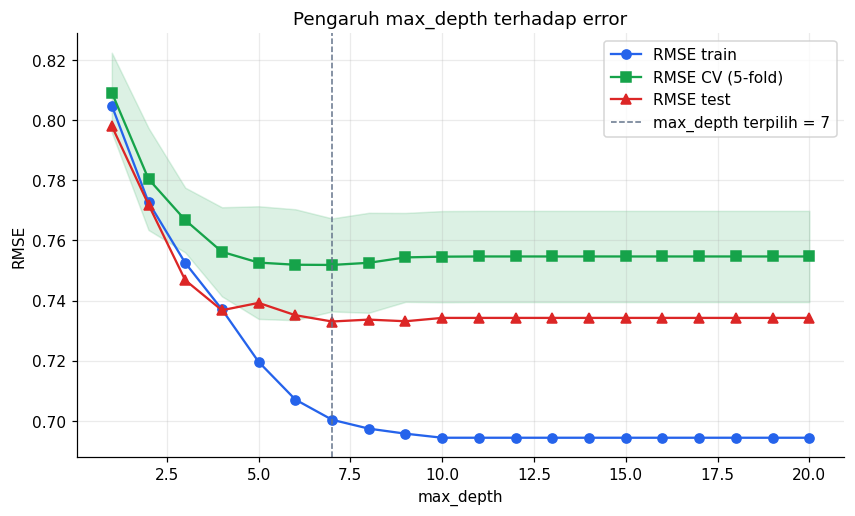

In [11]:
def plot_depth_curve_reg(model, best_depth):
    depths = list(range(1, 21))
    train_rmse, test_rmse, cv_rmse, cv_stds = [], [], [], []

    for depth in depths:
        fitted = clone(model).set_params(max_depth=depth).fit(X_train_r, y_train_r)
        train_rmse.append(root_mean_squared_error(y_train_r, fitted.predict(X_train_r)))
        test_rmse.append(root_mean_squared_error(y_test_r, fitted.predict(X_test_r)))
        scores = cross_val_score(
            clone(model).set_params(max_depth=depth),
            X_train_r, y_train_r, cv=cv_reg, scoring="neg_root_mean_squared_error", n_jobs=-1,
        )
        cv_rmse.append(-scores.mean())
        cv_stds.append(scores.std())

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(depths, train_rmse, "o-", color=COLORS["blue"], label="RMSE train")
    ax.plot(depths, cv_rmse, "s-", color=COLORS["green"], label="RMSE CV (5-fold)")
    ax.fill_between(depths,
                    np.array(cv_rmse) - np.array(cv_stds),
                    np.array(cv_rmse) + np.array(cv_stds),
                    color=COLORS["green"], alpha=0.15)
    ax.plot(depths, test_rmse, "^-", color=COLORS["red"], label="RMSE test")
    ax.axvline(best_depth, color=COLORS["gray"], linestyle="--", linewidth=1,
               label=f"max_depth terpilih = {best_depth}")
    ax.set_xlabel("max_depth")
    ax.set_ylabel("RMSE")
    ax.set_title("Pengaruh max_depth terhadap error")
    ax.legend()
    plt.show()


plot_depth_curve_reg(best_reg, best_reg.get_depth())

**Grafik Prediksi vs aktual model terbaik.**

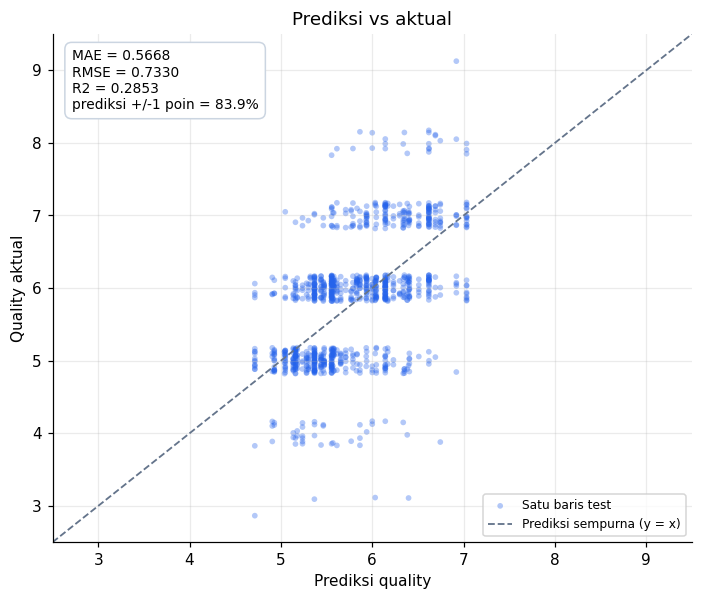

In [12]:
y_pred_reg = best_reg.predict(X_test_r)
metrics_reg = evaluate_reg(best_reg)
y_true_reg = y_test_r.to_numpy(dtype=float)
jitter = np.random.default_rng(RANDOM_STATE).uniform(-0.18, 0.18, len(y_true_reg))

fig, ax = plt.subplots(figsize=(7.5, 6))
ax.scatter(y_pred_reg, y_true_reg + jitter, s=14, alpha=0.35,
           color=COLORS["blue"], edgecolor="none", label="Satu baris test")
ax.plot([2.5, 9.5], [2.5, 9.5], "--", color=COLORS["gray"], linewidth=1.2,
        label="Prediksi sempurna (y = x)")
ax.set_xlim(2.5, 9.5)
ax.set_ylim(2.5, 9.5)
ax.set_xlabel("Prediksi quality")
ax.set_ylabel("Quality aktual")
ax.set_title("Prediksi vs aktual")
ax.text(0.03, 0.97,
        f"MAE = {metrics_reg['MAE']:.4f}\n"
        f"RMSE = {metrics_reg['RMSE']:.4f}\n"
        f"R2 = {metrics_reg['R2']:.4f}\n"
        f"prediksi +/-1 poin = {metrics_reg['dalam +/-1 poin']:.1%}",
        transform=ax.transAxes, va="top", fontsize=9,
        bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="#cbd5e1"))
ax.legend(loc="lower right", fontsize=8)
plt.show()

**Grafik Analisis residual.**

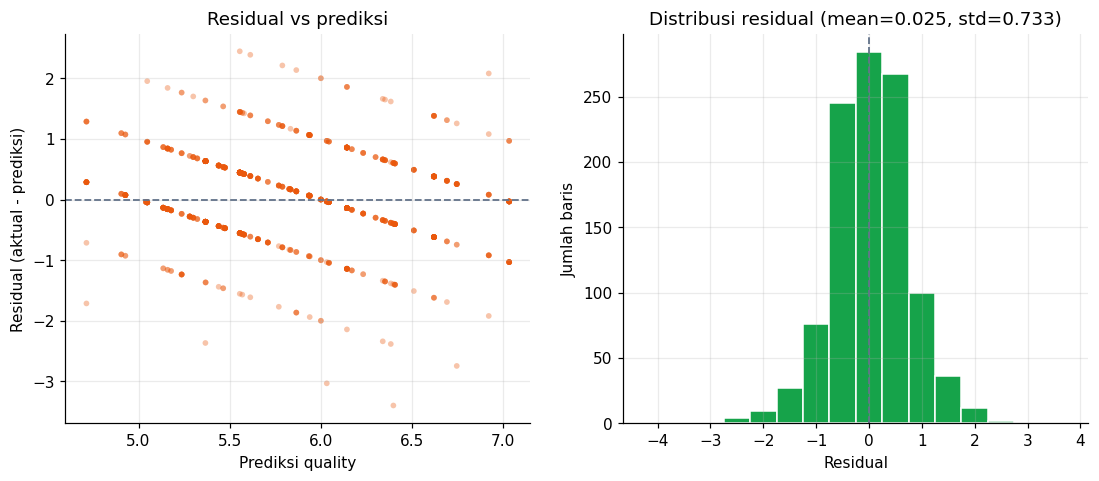

In [13]:
residual = y_true_reg - y_pred_reg

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].scatter(y_pred_reg, residual, s=14, alpha=0.35, color=COLORS["orange"], edgecolor="none")
axes[0].axhline(0, color=COLORS["gray"], linestyle="--", linewidth=1.2)
axes[0].set_xlabel("Prediksi quality")
axes[0].set_ylabel("Residual (aktual - prediksi)")
axes[0].set_title("Residual vs prediksi")

axes[1].hist(residual, bins=np.arange(-4.25, 4.25, 0.5), color=COLORS["green"], edgecolor="white")
axes[1].axvline(0, color=COLORS["gray"], linestyle="--", linewidth=1.2)
axes[1].set_xlabel("Residual")
axes[1].set_ylabel("Jumlah baris")
axes[1].set_title(f"Distribusi residual (mean={residual.mean():.3f}, std={residual.std():.3f})")
plt.show()

**Grafik Distribusi aktual vs prediksi per skor quality.**

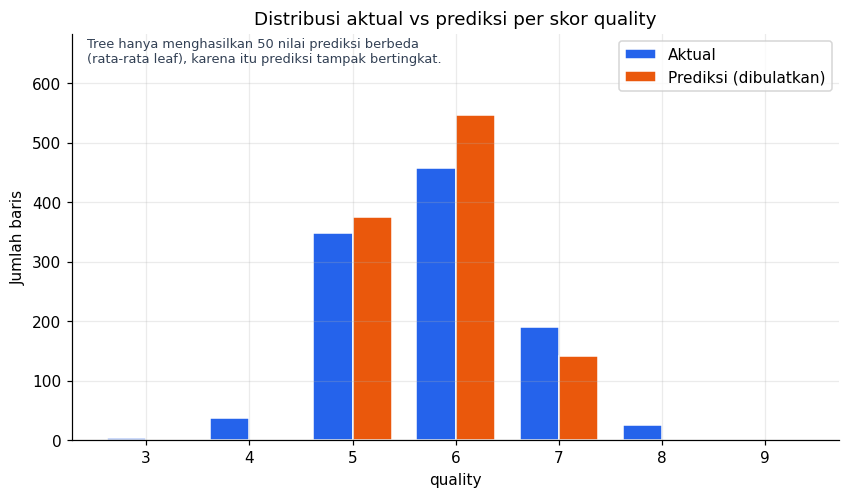

In [14]:
levels = np.arange(3, 10)
actual = np.array([np.sum(y_true_reg == level) for level in levels])
predicted = np.array([np.sum(np.clip(np.round(y_pred_reg), 3, 9) == level) for level in levels])
unique_pred = np.unique(np.round(y_pred_reg, 4))

fig, ax = plt.subplots(figsize=(9, 4.8))
width = 0.38
ax.bar(levels - width / 2, actual, width, label="Aktual",
       color=COLORS["blue"], edgecolor="white")
ax.bar(levels + width / 2, predicted, width, label="Prediksi (dibulatkan)",
       color=COLORS["orange"], edgecolor="white")
ax.set_xticks(levels)
ax.set_ylim(0, max(actual.max(), predicted.max()) * 1.25)
ax.set_xlabel("quality")
ax.set_ylabel("Jumlah baris")
ax.set_title("Distribusi aktual vs prediksi per skor quality")
ax.legend(loc="upper right")
ax.text(0.02, 0.99,
        f"Tree hanya menghasilkan {len(unique_pred)} nilai prediksi berbeda\n"
        f"(rata-rata leaf), karena itu prediksi tampak bertingkat.",
        transform=ax.transAxes, va="top", fontsize=8.5, color="#334155")
plt.show()

**Grafik Feature importance dan permutation importance.**

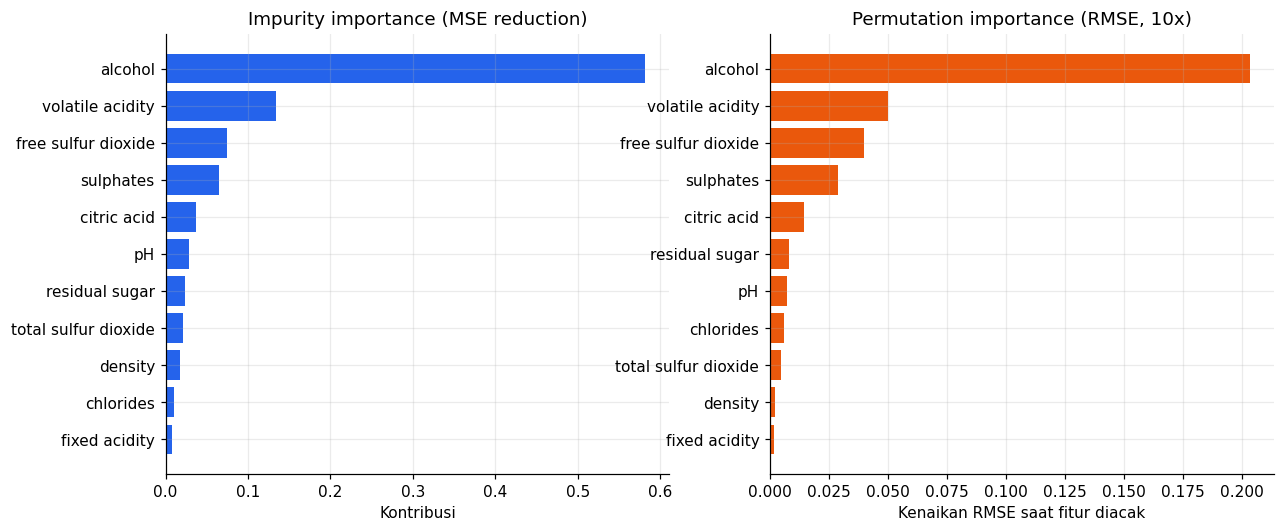

,impurity (MSE),permutation (RMSE),std
alcohol,0.5820,0.2033,0.0086
volatile acidity,0.1337,0.0499,0.0051
free sulfur dioxide,0.0741,0.0398,0.0051
sulphates,0.0643,0.0287,0.0044
citric acid,0.0364,0.0144,0.0053
residual sugar,0.0238,0.0079,0.0014
pH,0.0287,0.0071,0.0053
chlorides,0.0101,0.0059,0.0019
total sulfur dioxide,0.0216,0.0045,0.0012
density,0.0179,0.0020,0.0016


In [15]:
impurity_reg = pd.Series(best_reg.feature_importances_, index=FEATURES)
perm_reg = permutation_importance(
    best_reg, X_test_r, y_test_r, n_repeats=10, random_state=RANDOM_STATE,
    scoring="neg_root_mean_squared_error", n_jobs=-1,
)
importance_reg = pd.DataFrame({
    "impurity (MSE)": impurity_reg,
    "permutation (RMSE)": perm_reg.importances_mean,
    "std": perm_reg.importances_std,
}).sort_values("permutation (RMSE)", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
ordered_imp = impurity_reg.sort_values()
axes[0].barh(ordered_imp.index, ordered_imp.values, color=COLORS["blue"])
axes[0].set_title("Impurity importance (MSE reduction)")
axes[0].set_xlabel("Kontribusi")

ordered_perm = importance_reg.sort_values("permutation (RMSE)")
axes[1].barh(ordered_perm.index, ordered_perm["permutation (RMSE)"], color=COLORS["orange"])
axes[1].set_title("Permutation importance (RMSE, 10x)")
axes[1].set_xlabel("Kenaikan RMSE saat fitur diacak")
plt.show()

importance_reg.round(4)

**Grafik Learning curve regressor.**

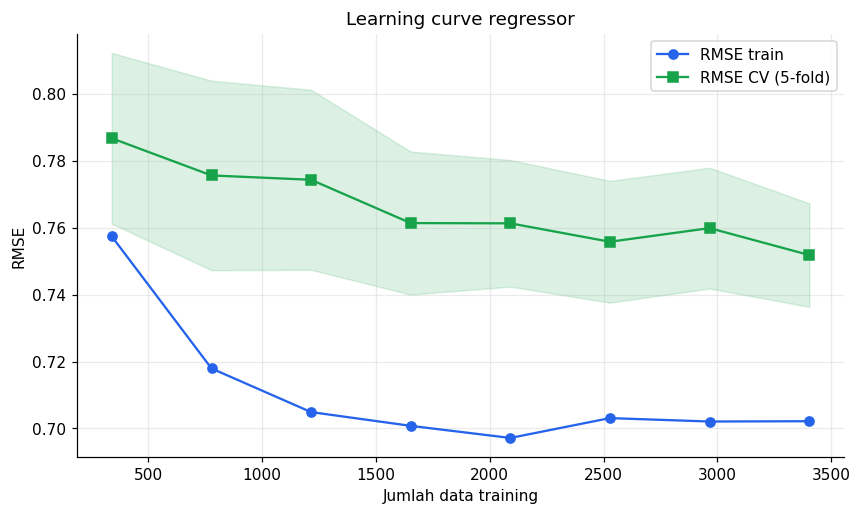

In [16]:
sizes, train_scores, cv_scores = learning_curve(
    best_reg, X_train_r, y_train_r, cv=cv_reg,
    train_sizes=np.linspace(0.1, 1.0, 8),
    scoring="neg_root_mean_squared_error", n_jobs=-1,
)
train_rmse = -train_scores.mean(axis=1)
cv_rmse_curve = -cv_scores.mean(axis=1)
cv_std = cv_scores.std(axis=1)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(sizes, train_rmse, "o-", color=COLORS["blue"], label="RMSE train")
ax.plot(sizes, cv_rmse_curve, "s-", color=COLORS["green"], label="RMSE CV (5-fold)")
ax.fill_between(sizes, cv_rmse_curve - cv_std, cv_rmse_curve + cv_std,
                color=COLORS["green"], alpha=0.15)
ax.set_xlabel("Jumlah data training")
ax.set_ylabel("RMSE")
ax.set_title("Learning curve regressor")
ax.legend()
plt.show()

**Grafik Struktur pohon regressor model terbaik.**

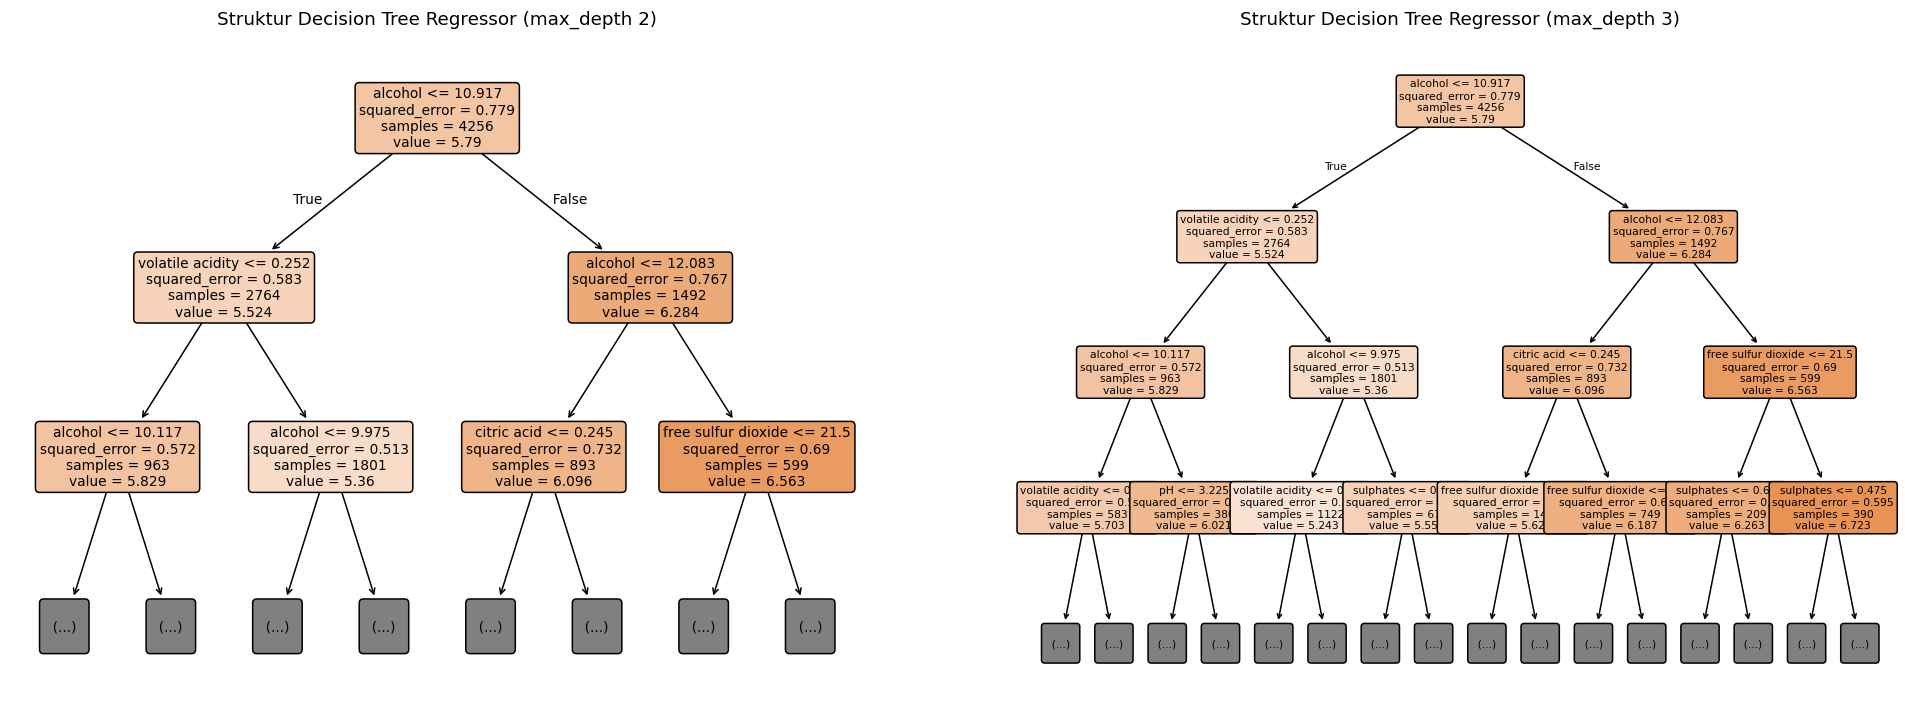

|--- alcohol <= 10.9167
|   |--- volatile acidity <= 0.2525
|   |   |--- alcohol <= 10.1167
|   |   |   |--- volatile acidity <= 0.2250
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- volatile acidity >  0.2250
|   |   |   |   |--- truncated branch of depth 3
|   |   |--- alcohol >  10.1167
|   |   |   |--- pH <= 3.2250
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- pH >  3.2250
|   |   |   |   |--- truncated branch of depth 3
|   |--- volatile acidity >  0.2525
|   |   |--- alcohol <= 9.9750
|   |   |   |--- volatile acidity <= 0.4225
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- volatile acidity >  0.4225
|   |   |   |   |--- truncated branch of depth 4
|   |   |--- alcohol >  9.9750
|   |   |   |--- sulphates <= 0.7250
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- sulphates >  0.7250
|   |   |   |   |--- value: [6.0441]
|--- alcohol >  10.9167
|   |--- alcohol <= 12.0833
|   |   |--- citric acid <= 0.2450
|

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(22, 8))
for ax, depth, fontsize in [(axes[0], 2, 9), (axes[1], 3, 7)]:
    plot_tree(
        best_reg, max_depth=depth, feature_names=FEATURES,
        filled=True, rounded=True, impurity=True, proportion=False,
        fontsize=fontsize, ax=ax,
    )
    ax.set_title(f"Struktur Decision Tree Regressor (max_depth {depth})")
plt.show()

print(export_text(best_reg, feature_names=FEATURES, max_depth=3, decimals=4))